#Unemployment Analysis with Python
**Goal:** clean and explore unemployment-rate data, visualize trends, and examine how the period around the COVID-19 shock differs from the earlier period.

**Dataset:** *Unemployment in India* (monthly state/region observations, with rural/urban breakdown). This is an India-focused dataset, not Pakistan data. Its time coverage is limited to 2019–2020, so conclusions must be restricted to that period.

**Important analytical caution:** before/after comparisons describe changes in the observed data; they do not prove that COVID-19 alone caused every change.



## Step 1 — Import libraries

In [4]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2 — Get the dataset
Try the public CSV link first. If it fails, download **Unemployment in India.csv** from the dataset repository linked below, then upload it when prompted.


In [5]:
import requests

DATA_URL = "/content/Unemployment in India.csv"

try:
    response = requests.get(DATA_URL, timeout=30)
    response.raise_for_status()
    df_raw = pd.read_csv(io.BytesIO(response.content))
    print("Dataset downloaded from public CSV URL.")
except Exception as error:
    print("Automatic download did not work:", error)
    print("Please upload the CSV file manually.")
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_name = next(name for name in uploaded if name.lower().endswith(".csv"))
        df_raw = pd.read_csv(io.BytesIO(uploaded[csv_name]))
    except Exception as upload_error:
        raise RuntimeError("Upload the Unemployment in India CSV and rerun this cell.") from upload_error

print("Raw shape:", df_raw.shape)
display(df_raw.head())

Automatic download did not work: Invalid URL '/content/Unemployment in India.csv': No scheme supplied. Perhaps you meant https:///content/Unemployment in India.csv?
Please upload the CSV file manually.


Saving Unemployment in India.csv to Unemployment in India (2).csv
Raw shape: (768, 7)


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


## Step 3 — Clean column names and inspect the dataset
Some copies of this dataset contain extra spaces in column names and blank rows. We normalize names, remove fully empty rows, and trim text values.

In [6]:
df = df_raw.copy()
df.columns = df.columns.str.strip()
df = df.dropna(how="all")

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype("string").str.strip()

print("Columns:", df.columns.tolist())
print("Shape after removing fully empty rows:", df.shape)
display(df.isna().sum().to_frame("missing_values"))
display(df.head())

Columns: ['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']
Shape after removing fully empty rows: (740, 7)


,missing_values
Region,0
Date,0
Frequency,0
Estimated Unemployment Rate (%),0
Estimated Employed,0
Estimated Labour Participation Rate (%),0
Area,0


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


## Step 4 — Convert columns to useful data types
The CSV uses human-readable column names. We verify the expected columns before continuing. Dates are parsed with `dayfirst=True` because many versions store dates like `31-05-2019`.

In [7]:
required = [
    "Region", "Date", "Estimated Unemployment Rate (%)",
    "Estimated Employed", "Estimated Labour Participation Rate (%)", "Area"
]
missing_columns = [c for c in required if c not in df.columns]
if missing_columns:
    raise ValueError(f"Expected columns not found: {missing_columns}. Check the CSV version.")

numeric_cols = [
    "Estimated Unemployment Rate (%)",
    "Estimated Employed",
    "Estimated Labour Participation Rate (%)"
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["Date"] = pd.to_datetime(df["Date"], errors="coerce", dayfirst=True)
df = df.dropna(subset=["Region", "Date", "Estimated Unemployment Rate (%)"])
df["Region"] = df["Region"].astype(str).str.strip()
df["Area"] = df["Area"].astype(str).str.strip().str.title()
df["YearMonth"] = df["Date"].dt.to_period("M").dt.to_timestamp()
df = df.drop_duplicates()

print("Cleaned shape:", df.shape)
print("Date range:", df["Date"].min(), "to", df["Date"].max())
display(df[numeric_cols].describe().T)

Cleaned shape: (740, 8)
Date range: 2019-05-31 00:00:00 to 2020-06-30 00:00:00


,count,mean,std,min,25%,50%,75%,max
Estimated Unemployment Rate (%),740.0,1.178795e+01,1.072130e+01,0.00,4.657500e+00,8.35,1.588750e+01,76.74
Estimated Employed,740.0,7.204460e+06,8.087988e+06,49420.00,1.190404e+06,4744178.50,1.127549e+07,45777509.00
Estimated Labour Participation Rate (%),740.0,4.263012e+01,8.111094e+00,13.33,3.806250e+01,41.16,4.550500e+01,72.57


**Interpretation:** the unemployment rate is a percentage; `Estimated Employed` is a count estimate. Do not add or average counts as if they were percentages.

## Step 5 — Overall unemployment trend over time
We calculate the simple mean of the reported regional observations for each month. This is a descriptive average across rows, not a population-weighted national unemployment rate.

,YearMonth,Estimated Unemployment Rate (%)
0,2019-05-01,8.874259
1,2019-06-01,9.303333
2,2019-07-01,9.033889
3,2019-08-01,9.637925
4,2019-09-01,9.051731


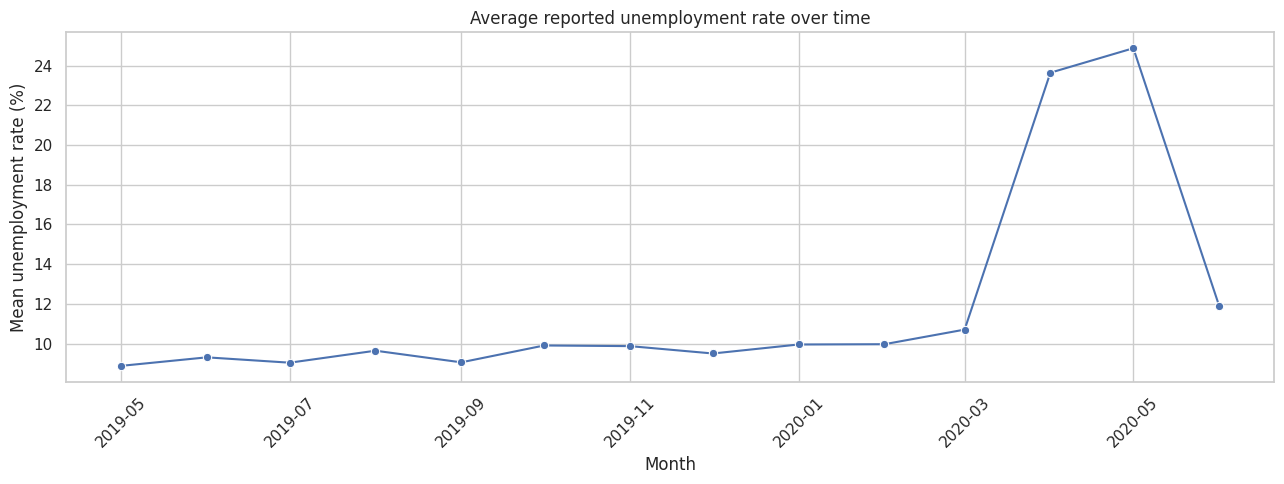

In [8]:
monthly = (
    df.groupby("YearMonth", as_index=False)["Estimated Unemployment Rate (%)"]
      .mean()
      .sort_values("YearMonth")
)
display(monthly.head())

plt.figure(figsize=(13, 5))
sns.lineplot(data=monthly, x="YearMonth", y="Estimated Unemployment Rate (%)", marker="o")
plt.title("Average reported unemployment rate over time")
plt.xlabel("Month")
plt.ylabel("Mean unemployment rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Step 6 — Compare regional unemployment
This ranks regions by their average reported unemployment rate across the available observations.

,average_unemployment_rate_pct
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


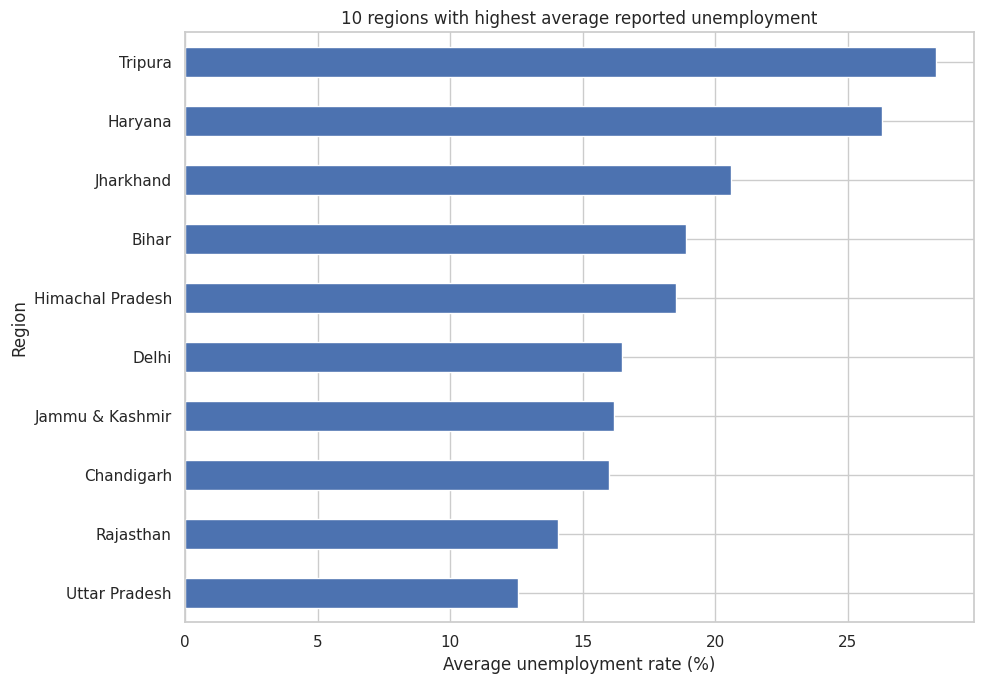

In [9]:
region_avg = (
    df.groupby("Region")["Estimated Unemployment Rate (%)"]
      .mean()
      .sort_values(ascending=False)
)
display(region_avg.head(10).to_frame("average_unemployment_rate_pct"))

plt.figure(figsize=(10, 7))
region_avg.head(10).sort_values().plot(kind="barh")
plt.title("10 regions with highest average reported unemployment")
plt.xlabel("Average unemployment rate (%)")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

## Step 7 — Urban versus rural comparison
The dataset includes an `Area` field. Compare monthly means for the two area categories where available.

,YearMonth,Area,Estimated Unemployment Rate (%)
0,2019-05-01,Rural,7.068077
1,2019-05-01,Urban,10.551429
2,2019-06-01,Rural,8.201154
3,2019-06-01,Urban,10.326786
4,2019-07-01,Rural,7.741923


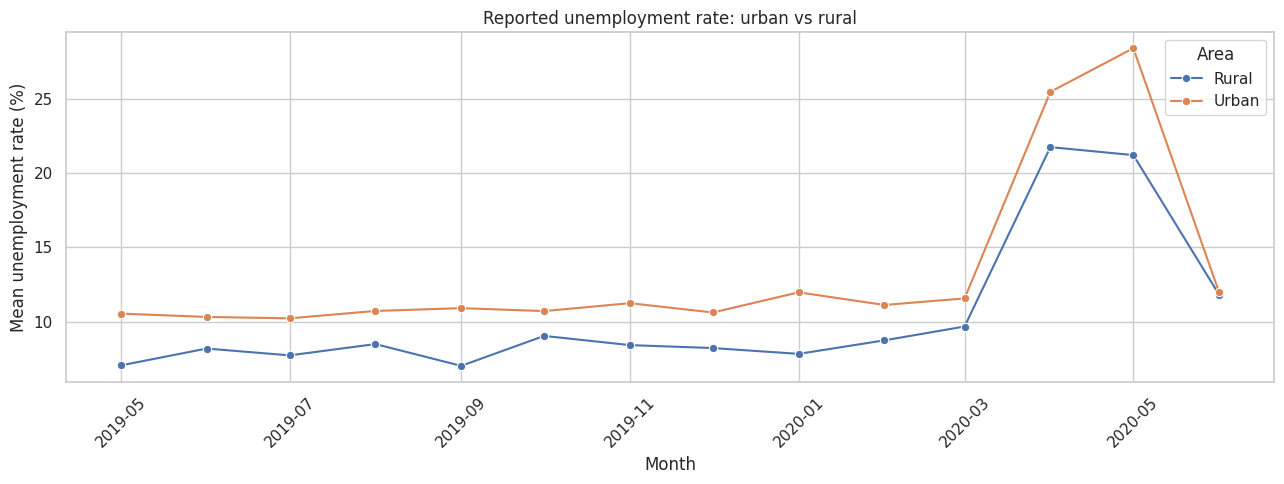

In [10]:
area_monthly = (
    df.groupby(["YearMonth", "Area"], as_index=False)["Estimated Unemployment Rate (%)"]
      .mean()
)
display(area_monthly.head())

plt.figure(figsize=(13, 5))
sns.lineplot(
    data=area_monthly, x="YearMonth",
    y="Estimated Unemployment Rate (%)", hue="Area", marker="o"
)
plt.title("Reported unemployment rate: urban vs rural")
plt.xlabel("Month")
plt.ylabel("Mean unemployment rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Step 8 — Examine the COVID-19 period
For a transparent descriptive comparison, use:
- **Before COVID comparison window:** observations before 1 March 2020.
- **COVID-era comparison window:** observations from 1 March 2020 onward.

The second group may contain only a few months. Report the exact date coverage and avoid causal claims.

,count,mean,median,std
Period,,,,
Before Mar 2020,536,9.509534,7.115,7.358863
Mar 2020 onward,204,17.774363,14.520,15.033663


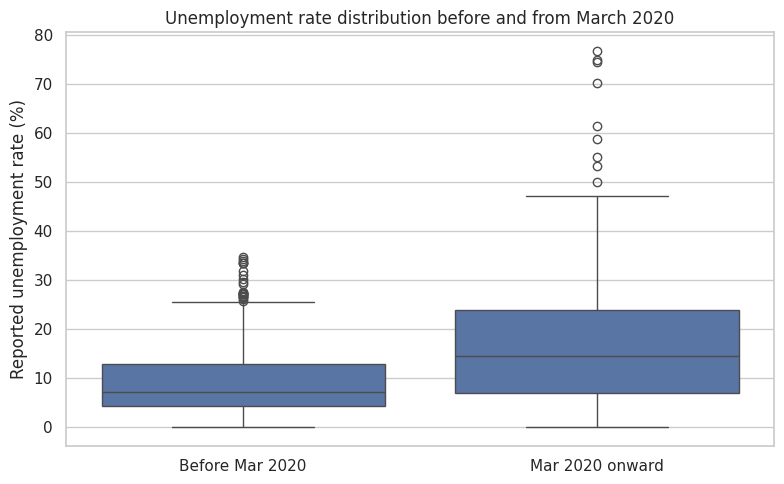

Difference in descriptive means: 8.26 percentage points


In [11]:
cutoff = pd.Timestamp("2020-03-01")
df["Period"] = np.where(df["Date"] < cutoff, "Before Mar 2020", "Mar 2020 onward")

period_summary = (
    df.groupby("Period")["Estimated Unemployment Rate (%)"]
      .agg(["count", "mean", "median", "std"])
)
display(period_summary)

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Period", y="Estimated Unemployment Rate (%)")
plt.title("Unemployment rate distribution before and from March 2020")
plt.xlabel("")
plt.ylabel("Reported unemployment rate (%)")
plt.tight_layout()
plt.show()

if set(["Before Mar 2020", "Mar 2020 onward"]).issubset(period_summary.index):
    before = period_summary.loc["Before Mar 2020", "mean"]
    during = period_summary.loc["Mar 2020 onward", "mean"]
    print(f"Difference in descriptive means: {during - before:.2f} percentage points")
else:
    print("One comparison period is absent; check the dataset's date coverage.")

## Step 9 — Monthly pattern / heatmap
A region-by-month heatmap makes it easier to see where and when reported unemployment was higher. We limit it to the 15 regions with the highest average rate to keep labels readable.

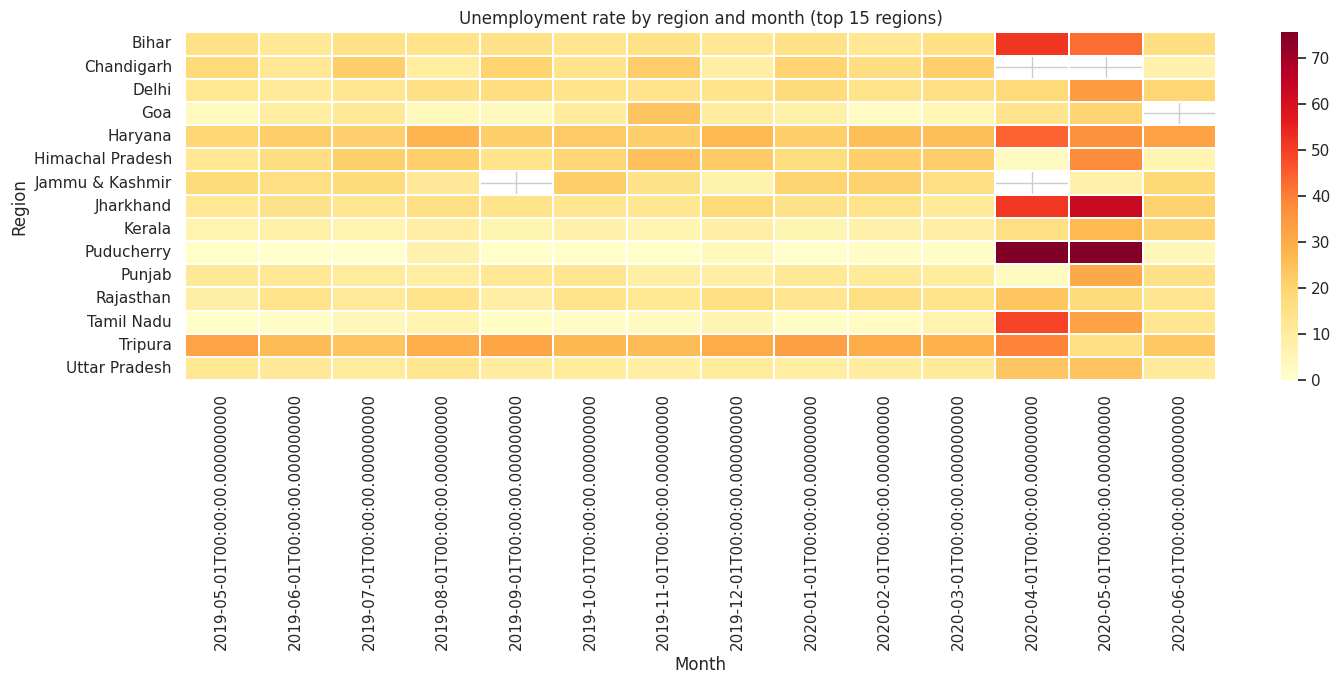

In [12]:
top_regions = region_avg.head(15).index
heatmap_data = (
    df[df["Region"].isin(top_regions)]
      .pivot_table(
          index="Region", columns="YearMonth",
          values="Estimated Unemployment Rate (%)", aggfunc="mean"
      )
)
plt.figure(figsize=(15, 7))
sns.heatmap(heatmap_data, cmap="YlOrRd", linewidths=0.2)
plt.title("Unemployment rate by region and month (top 15 regions)")
plt.xlabel("Month")
plt.ylabel("Region")
plt.tight_layout()
plt.show()

## Step 10 — Generate findings from your actual results
Run this cell and use the printed values to write your report. These are descriptive statistics from this CSV, not official current unemployment figures.

In [13]:
highest_region = region_avg.index[0]
lowest_region = region_avg.index[-1]
highest_value = region_avg.iloc[0]
lowest_value = region_avg.iloc[-1]
peak_month_row = monthly.loc[monthly["Estimated Unemployment Rate (%)"].idxmax()]

print(f"Highest average region: {highest_region} ({highest_value:.2f}%)")
print(f"Lowest average region: {lowest_region} ({lowest_value:.2f}%)")
print(
    "Highest monthly mean:",
    peak_month_row["YearMonth"].strftime("%Y-%m"),
    f"({peak_month_row['Estimated Unemployment Rate (%)']:.2f}%)"
)
print("Area categories:", sorted(df["Area"].dropna().unique().tolist()))

Highest average region: Tripura (28.35%)
Lowest average region: Meghalaya (4.80%)
Highest monthly mean: 2020-05 (24.88%)
Area categories: ['Rural', 'Urban']


## Step 11 — Export cleaned data and summary tables

In [14]:
df.to_csv("unemployment_cleaned.csv", index=False)
monthly.to_csv("monthly_unemployment_summary.csv", index=False)
region_avg.rename("average_unemployment_rate_pct").to_csv("regional_unemployment_summary.csv")
print("Saved cleaned data and summary CSV files.")
try:
    from google.colab import files
    files.download("unemployment_cleaned.csv")
    files.download("monthly_unemployment_summary.csv")
    files.download("regional_unemployment_summary.csv")
except ImportError:
    print("Files are saved in the current working directory.")

Saved cleaned data and summary CSV files.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion template
Fill in the blanks from your outputs:

> This project analyzed unemployment observations across Indian regions during **[start date] to [end date]**. After cleaning missing and malformed records, I examined monthly trends, regional differences, urban-rural patterns, and descriptive differences before and from March 2020 onward. The highest regional average was **[region and rate]**, and the month with the highest mean was **[month and rate]**. The comparison indicates **[describe what your chart shows]**. These findings are descriptive and do not establish that COVID-19 was the sole cause of the observed changes.

**Limitations:** the dataset covers a short historical period, has regional observations rather than a complete current national time series, and the simple row mean is not weighted by labour force. The dataset is about India, as required by the selected dataset—not Pakistan.